
# Phase 1: Data Quality and Understanding

## Objective

The objective of this phase is to understand and validate the steel industry energy consumption dataset before performing exploratory data analysis, feature engineering, and machine learning.

This phase examines:
- Dataset structure and column definitions
- Missing values and duplicate records
- Timestamp validity and chronological order
- Consistency of the 15-minute sampling interval
- Energy consumption distribution
- Zero and unusually high consumption readings

**Data quality principle:** Unusual observations will be flagged for investigation rather than automatically removed. High consumption may represent genuine industrial activity and should not be treated as an error without supporting evidence.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Dataset path
DATA_PATH = Path("Steel_industry_data.csv")

# Check whether the dataset exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Place the CSV in the notebook folder or update DATA_PATH."
    )

# Load raw dataset
df_raw = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")


Dataset loaded successfully!
Rows: 35,040
Columns: 11



## 1. Dataset Overview

This section examines the dataset's dimensions, column names, data types, and initial records. These checks establish the structure of the raw data before any cleaning or transformation is performed.


In [2]:

print("Dataset shape:", df_raw.shape)

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes.to_frame(name="Data Type"))

print("\nFirst five records:")
display(df_raw.head())

print("\nRandom sample:")
display(df_raw.sample(min(5, len(df_raw)), random_state=42))


Dataset shape: (35040, 11)

Column names:
['date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']

Data types:


,Data Type
date,object
Usage_kWh,float64
Lagging_Current_Reactive.Power_kVarh,float64
Leading_Current_Reactive_Power_kVarh,float64
CO2(tCO2),float64
Lagging_Current_Power_Factor,float64
Leading_Current_Power_Factor,float64
NSM,int64
WeekStatus,object
Day_of_week,object



First five records:


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01-01-2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01-01-2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01-01-2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01-01-2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01-01-2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load



Random sample:


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
11356,29-04-2018 07:15,2.88,3.82,0.0,0.00,60.20,100.00,26100,Weekend,Sunday,Light_Load
26543,04-10-2018 12:00,60.77,48.02,0.0,0.03,78.46,100.00,43200,Weekday,Thursday,Maximum_Load
2445,26-01-2018 11:30,120.42,59.65,0.0,0.06,89.61,100.00,41400,Weekday,Friday,Maximum_Load
14649,02-06-2018 14:30,3.13,0.00,16.6,0.00,100.00,18.53,52200,Weekend,Saturday,Light_Load
32699,07-12-2018 15:00,58.86,20.99,0.0,0.03,94.19,100.00,54000,Weekday,Friday,Medium_Load



## 2. Schema Validation

Verify that all expected variables are present. Missing required columns may indicate that the wrong file was loaded or that the dataset schema has changed.


In [3]:

required_columns = [
    "date",
    "Usage_kWh",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "NSM",
    "WeekStatus",
    "Day_of_week",
    "Load_Type"
]

missing_columns = [
    col for col in required_columns
    if col not in df_raw.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Schema validation passed.")
print(f"Expected columns found: {len(required_columns)}")


Schema validation passed.
Expected columns found: 11



## 3. Missing Values and Duplicate Records

Missing values and duplicate records can affect statistical analysis and model evaluation. This section checks missingness by column, exact duplicate rows, and duplicate timestamp strings in the original dataset.


In [5]:

# Missing values
missing_values = df_raw.isnull().sum()

print("Missing values by column:")
display(missing_values.to_frame(name="Missing Count"))

print("Total missing cells:", int(df_raw.isnull().sum().sum()))

# Exact duplicate rows
duplicate_rows = int(df_raw.duplicated().sum())
print("\nExact duplicate rows:", duplicate_rows)

# Duplicate raw timestamp strings
duplicate_dates = int(df_raw["date"].duplicated().sum())
print("Duplicate date strings:", duplicate_dates)


Missing values by column:


,Missing Count
date,0
Usage_kWh,0
Lagging_Current_Reactive.Power_kVarh,0
Leading_Current_Reactive_Power_kVarh,0
CO2(tCO2),0
Lagging_Current_Power_Factor,0
Leading_Current_Power_Factor,0
NSM,0
WeekStatus,0
Day_of_week,0


Total missing cells: 0

Exact duplicate rows: 0
Duplicate date strings: 0



## 4. Timestamp Validation and Chronological Ordering

The dataset records energy consumption at 15-minute intervals. Timestamp values are parsed into a datetime format and sorted chronologically.

After sorting, we check timestamp uniqueness and identify intervals that differ from the expected 15-minute frequency.


In [7]:

df = df_raw.copy()

df["timestamp"] = pd.to_datetime(
    df["date"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

invalid_timestamps = int(df["timestamp"].isna().sum())

print("Invalid timestamps:", invalid_timestamps)

if invalid_timestamps > 0:
    display(df.loc[df["timestamp"].isna(), ["date"]].head(20))
    raise ValueError("Resolve invalid timestamps before continuing.")

# Check original order
chronological_before = df["timestamp"].is_monotonic_increasing

# Sort chronologically
df = df.sort_values(
    "timestamp",
    kind="stable"
).reset_index(drop=True)

print("Chronological before sorting:", chronological_before)
print("Chronological after sorting:", df["timestamp"].is_monotonic_increasing)
print("Duplicate parsed timestamps:", int(df["timestamp"].duplicated().sum()))

print("First timestamp:", df["timestamp"].min())
print("Last timestamp:", df["timestamp"].max())


Invalid timestamps: 0
Chronological before sorting: False
Chronological after sorting: True
Duplicate parsed timestamps: 0
First timestamp: 2018-01-01 00:00:00
Last timestamp: 2018-12-31 23:45:00



## 5. Sampling Frequency and Time Gaps

Check the difference between consecutive timestamps. The expected interval is 15 minutes.

Intervals that differ from this expectation are reported for investigation. They may indicate missing observations, irregular timestamps, or duplicate-time issues.


In [9]:

expected_interval = pd.Timedelta(minutes=15)

time_intervals = df["timestamp"].diff().dropna()

interval_counts = (
    time_intervals.value_counts()
    .rename_axis("Time Interval")
    .to_frame("Count")
)

print("Most common timestamp intervals:")
display(interval_counts.head(10))

incorrect_intervals = time_intervals[
    time_intervals != expected_interval
]

print(
    "Intervals other than 15 minutes:",
    len(incorrect_intervals)
)

if not incorrect_intervals.empty:
    print("\nExamples of unexpected intervals:")
    display(incorrect_intervals.head(20).to_frame("Observed Interval"))


Most common timestamp intervals:


,Count
Time Interval,
0 days 00:15:00,35039


Intervals other than 15 minutes: 0



## 6. Energy Consumption Distribution

Examine the descriptive statistics and distribution of `Usage_kWh`, the energy consumption variable measured for each 15-minute observation.

The analysis includes the mean, median, standard deviation, range, selected percentiles, and a histogram to understand variability and skewness.


Descriptive statistics:


,Usage_kWh
count,35040.000000
mean,27.386892
std,33.444380
min,0.000000
25%,3.200000
50%,4.570000
75%,51.237500
max,157.180000



Selected percentiles:


,Usage_kWh
0.01,2.5900
0.25,3.2000
0.50,4.5700
0.75,51.2375
0.90,78.0840
0.95,99.0400
0.99,122.7083
1.00,157.1800


Zero readings: 1
Negative readings: 0


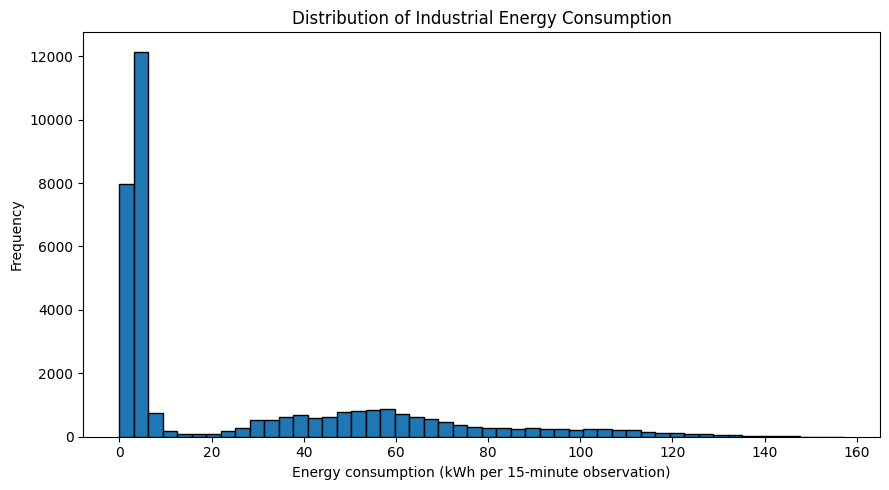

In [10]:

target_col = "Usage_kWh"

df[target_col] = pd.to_numeric(
    df[target_col],
    errors="coerce"
)

if df[target_col].isna().any():
    raise ValueError("Usage_kWh contains missing or non-numeric values.")

print("Descriptive statistics:")
display(df[target_col].describe().to_frame(name="Usage_kWh"))

print("\nSelected percentiles:")
display(
    df[target_col]
    .quantile([0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
    .to_frame(name="Usage_kWh")
)

print("Zero readings:", int((df[target_col] == 0).sum()))
print("Negative readings:", int((df[target_col] < 0).sum()))

plt.figure(figsize=(9, 5))
plt.hist(df[target_col], bins=50, edgecolor="black")
plt.xlabel("Energy consumption (kWh per 15-minute observation)")
plt.ylabel("Frequency")
plt.title("Distribution of Industrial Energy Consumption")
plt.tight_layout()
plt.show()



## 7. Zero and High-Consumption Observations

Zero-consumption readings and unusually high readings are flagged for further investigation.

The 99th percentile is used as a descriptive screening threshold. It is not a physical operating limit, and exceeding it does not prove that a measurement is erroneous.

All observations are retained at this stage.


In [11]:

# Calculate the 99th-percentile threshold
p99 = df[target_col].quantile(0.99)

# Create review flags
df["zero_usage_flag"] = df[target_col].eq(0)
df["high_usage_flag"] = df[target_col] > p99

print(f"99th-percentile threshold: {p99:.4f} kWh")
print("Zero readings flagged:", int(df["zero_usage_flag"].sum()))
print("High readings flagged:", int(df["high_usage_flag"].sum()))

# Inspect zero-consumption observations
zero_rows = df[df["zero_usage_flag"]]

print("\nZero-consumption observations:")
display(zero_rows)

# Inspect the highest readings
review_columns = [
    "timestamp",
    "Usage_kWh",
    "zero_usage_flag",
    "high_usage_flag"
]

print("\nTen highest consumption readings:")
display(df.nlargest(10, target_col)[review_columns])


99th-percentile threshold: 122.7083 kWh
Zero readings flagged: 1
High readings flagged: 351

Zero-consumption observations:


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,timestamp,zero_usage_flag,high_usage_flag
29760,07-11-2018 00:00,0.0,0.0,0.0,0.0,0.0,0.0,0,Weekday,Wednesday,Light_Load,2018-11-07,True,False



Ten highest consumption readings:


,timestamp,Usage_kWh,zero_usage_flag,high_usage_flag
31239,2018-11-22 09:45:00,157.18,False,True
1399,2018-01-15 13:45:00,153.14,False,True
31724,2018-11-27 11:00:00,151.67,False,True
7813,2018-03-23 09:15:00,151.31,False,True
1702,2018-01-18 17:30:00,149.65,False,True
33849,2018-12-19 14:15:00,149.18,False,True
163,2018-01-02 16:45:00,147.46,False,True
6112,2018-03-05 16:00:00,146.88,False,True
1680,2018-01-18 12:00:00,146.48,False,True
448,2018-01-05 16:00:00,146.34,False,True



## 8. Final Validation and Export

Perform final structural and temporal checks before saving the dataset.

The output retains all observations, adds a parsed timestamp and review flags, and is saved for use in subsequent research phases.


In [12]:

# Final validation checks
assert df["timestamp"].notna().all(), "Missing timestamps found."
assert df["timestamp"].is_monotonic_increasing, "Timestamps are not sorted."
assert df["timestamp"].is_unique, "Duplicate timestamps remain."
assert df[target_col].notna().all(), "Missing consumption values found."

final_intervals = df["timestamp"].diff().dropna()

incorrect_interval_count = int(
    (final_intervals != expected_interval).sum()
)

print("FINAL VALIDATION SUMMARY")
print("-" * 35)
print("Rows retained:", f"{len(df):,}")
print("Columns in output:", df.shape[1])
print("Timestamps sorted:", df["timestamp"].is_monotonic_increasing)
print("Timestamps unique:", df["timestamp"].is_unique)
print("Unexpected intervals:", incorrect_interval_count)
print("Zero readings flagged:", int(df["zero_usage_flag"].sum()))
print("High readings flagged:", int(df["high_usage_flag"].sum()))
print("Rows automatically deleted: 0")

# Export cleaned dataset
df.to_csv("steel_industry_clean.csv", index=False)

# Export observations requiring review
review_rows = df[
    df["zero_usage_flag"] | df["high_usage_flag"]
]

review_rows.to_csv(
    "phase1_observations_for_review.csv",
    index=False
)

print("\nFiles saved successfully:")
print("- steel_industry_clean.csv")
print("- phase1_observations_for_review.csv")


FINAL VALIDATION SUMMARY
-----------------------------------
Rows retained: 35,040
Columns in output: 14
Timestamps sorted: True
Timestamps unique: True
Unexpected intervals: 0
Zero readings flagged: 1
High readings flagged: 351
Rows automatically deleted: 0

Files saved successfully:
- steel_industry_clean.csv
- phase1_observations_for_review.csv



## 9. Interpretation and Limitations

- Chronological sorting verifies the time order but does not establish the physical accuracy of each measurement.
- A zero-consumption observation may represent an operational shutdown or a measurement issue; further evidence is required to distinguish between these explanations.
- High-consumption observations are retained because extreme values may reflect genuine industrial activity.
- The 99th-percentile threshold is used only to identify observations for review.
- Before forecasting, the availability of variables such as `Load_Type` and `CO2(tCO2)` at the prediction time must be assessed to avoid information leakage.

The dataset is now prepared for subsequent exploratory analysis and feature engineering, subject to review of any reported data-quality issues.
